In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

df = pd.read_csv("clean_dataset.csv")

df["datetime"] = pd.to_datetime(df["datetime"], utc=True)

# time features
df["hour"] = df["datetime"].dt.hour
df["dayofweek"] = df["datetime"].dt.dayofweek
df["month"] = df["datetime"].dt.month

# Replace "-" strings with NaN everywhere
df = df.replace("-", np.nan)
df = df.dropna().reset_index(drop=True)

df.head()

,datetime,value,lat,lon,temperature,pressure,humidity,precipitation,snow_depth,wind_speed,cloud_cover,Nitrogen dioxide [µg/m3],Ozone [µg/m3],Inhalable particles <10 µm [µg/m3],Fine particles <2.5 µm [µg/m3],Black carbon [µg/m3],hour,dayofweek,month
0,2023-11-15 12:00:00+00:00,21,60.17577,24.949638,0.7,1008.6,81.3,0.0,0.0,4.0,7.0,12.4,37.8,17.4,6.3,0.2,12,2,11
1,2023-11-15 13:00:00+00:00,19,60.17577,24.949638,0.7,1009.0,81.2,0.0,0.0,3.7,8.0,17.7,33.9,17.6,5.8,0.2,13,2,11
2,2023-11-15 14:00:00+00:00,21,60.17577,24.949638,0.8,1009.4,80.8,0.0,0.0,4.4,8.0,17.5,34.3,18.1,5.6,0.3,14,2,11
3,2023-11-15 15:00:00+00:00,27,60.17577,24.949638,0.8,1009.9,78.9,0.0,0.0,3.8,8.0,18.6,34.9,18.8,6.5,0.3,15,2,11
4,2023-11-15 16:00:00+00:00,20,60.17577,24.949638,0.6,1010.3,79.3,0.0,0.0,3.6,7.0,21.3,33.5,20.4,5.5,0.4,16,2,11


## 1. Model setup

# Weather affects Traffic volume (value): How does weather uncertainty affect traffic volume?
Input: temperature,	pressure,	humidity,	precipitation,	snow_depth,	wind_speed,	cloud_cover, hour, dayofweek, month
Output: Traffic (value)

# Traffic + weather affects air pollution: How does traffic impact air pollution?
Input: Traffic, weather variables
Output: N02, BC

In [29]:
## weather --> traffic

# Input
weather_cols = [
    "temperature", "precipitation", "snow_depth",
    "wind_speed", "humidity", "pressure", "cloud_cover",
    "hour", "dayofweek", "month"
]

# convert to numbers
for c in weather_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

 # Output
y_traffic = df["value"]  # traffic volume

# Fit model
X_weather = df[weather_cols]

traffic_model = LinearRegression()
traffic_model.fit(X_weather, y_traffic)

LinearRegression()

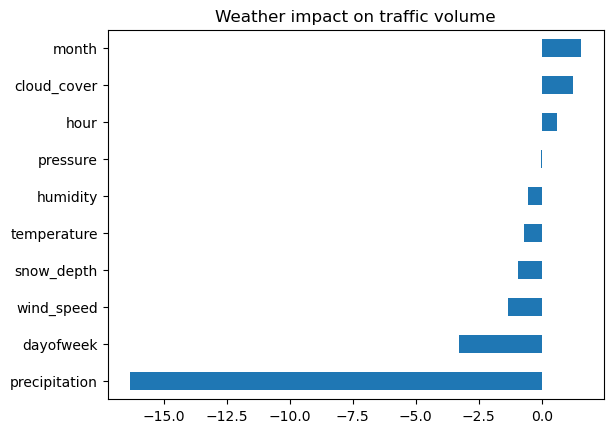

In [30]:
# Sensitivity weather --> traffic
coefs = pd.Series(traffic_model.coef_, index=weather_cols)
coefs.sort_values().plot(kind="barh")
plt.title("Weather impact on traffic volume")
plt.show()

In [31]:
## Traffic + weather --> air pollution

# input
X_pollution = df[weather_cols + ["value"]]

# output
y_no2 = df["Nitrogen dioxide [µg/m3]"]
y_bc  = df["Black carbon [µg/m3]"]

# fit model
no2_model = LinearRegression()
bc_model  = LinearRegression()

no2_model.fit(X_pollution, y_no2)
bc_model.fit(X_pollution, y_bc)

LinearRegression()

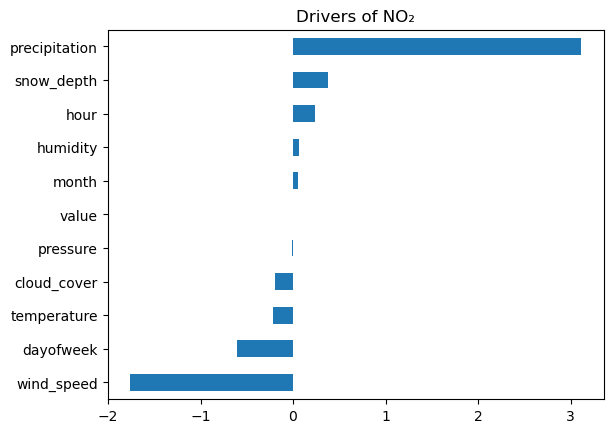

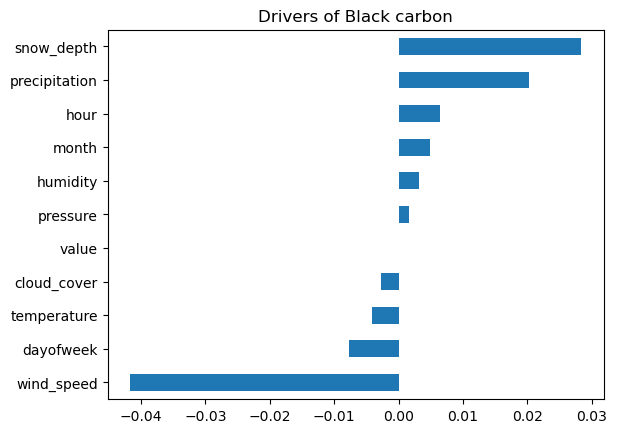

In [32]:
# Sensitivity traffic + weather --> air pollution
pd.Series(no2_model.coef_, index=X_pollution.columns)\
  .sort_values().plot(kind="barh")
plt.title("Drivers of NO₂")
plt.show()

pd.Series(bc_model.coef_, index=X_pollution.columns)\
  .sort_values().plot(kind="barh")
plt.title("Drivers of Black carbon")
plt.show()


## 2. Basic model analyzing techniques

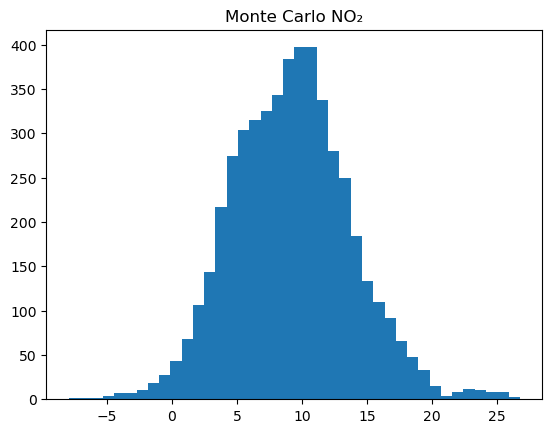

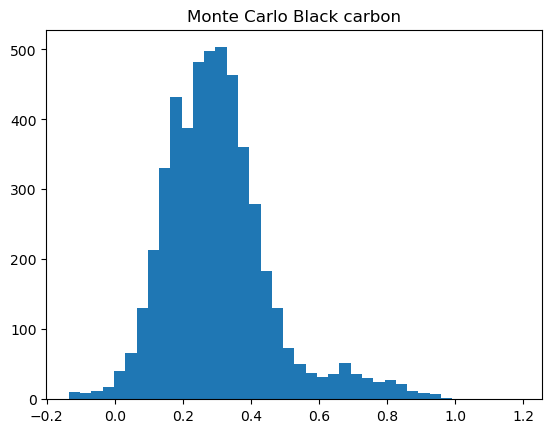

In [41]:
## Uncertainty analysis Monte Carlo

# sample weather
N = 5000

weather_samples = df[weather_cols].sample(N, replace=True).reset_index(drop=True)

# generate traffic
traffic_mc = traffic_model.predict(weather_samples)

# policy variable
R = 0.2  # 20% traffic reduction
traffic_mc_policy = traffic_mc * (1 - R)

# predict pollution
X_mc = weather_samples.copy()
X_mc["value"] = traffic_mc_policy

no2_mc = no2_model.predict(X_mc)
bc_mc  = bc_model.predict(X_mc)

# Monte Carlo distributions
plt.hist(no2_mc, bins=40)
plt.title("Monte Carlo NO₂")
plt.show()

plt.hist(bc_mc, bins=40)
plt.title("Monte Carlo Black carbon")
plt.show()

In [42]:
## Scenario analysis 

for R in [0.0, 0.2, 0.4]:
    X_mc["value"] = traffic_mc * (1 - R)
    no2 = no2_model.predict(X_mc)

    p5, p50, p95 = np.percentile(no2, [5, 50, 95])

    print(f"R={R}: NO₂ p5={p5:.3f}, median={p50:.3f}, p95={p95:.3f}")



R=0.0: NO₂ p5=2.199, median=9.190, p95=16.920
R=0.2: NO₂ p5=2.198, median=9.188, p95=16.920
R=0.4: NO₂ p5=2.197, median=9.185, p95=16.919


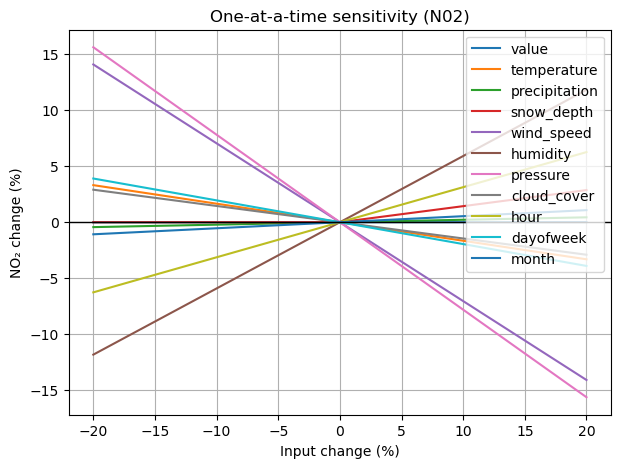

In [78]:
## one-at-a-time sensitivity

oat_vars = [
    "value",          # traffic
     "temperature", "precipitation", "snow_depth",
    "wind_speed", "humidity", "pressure", "cloud_cover",
    "hour", "dayofweek", "month"
]
feature_cols = list(X_pollution.columns)
# Percentage changes
steps = np.array([-0.2, -0.1, 0.0, 0.1, 0.2])

# Baseline (typical conditions)
base = df[feature_cols].median()

# Baseline NO2
y0 = no2_model.predict(pd.DataFrame([base]))[0]

plt.figure(figsize=(7,5))

for var in oat_vars:
    y_vals = []

    for s in steps:
        x = base.copy()

        # Change only ONE variable
        if x[var] == 0:
            x[var] = df[var].std() * s
        else:
            x[var] = x[var] * (1 + s)

        # No negative values for physical variables
        if var in ["snow_depth"]:
            x[var] = max(0, x[var])

        y = no2_model.predict(pd.DataFrame([x]))[0]
        y_vals.append(100 * (y - y0) / y0)  # % change

    plt.plot(steps * 100, y_vals, label=var)

plt.axhline(0, color="black", linewidth=1)
plt.xlabel("Input change (%)")
plt.ylabel("NO₂ change (%)")
plt.title("One-at-a-time sensitivity (N02)")
plt.legend()
plt.grid(True)
plt.show()

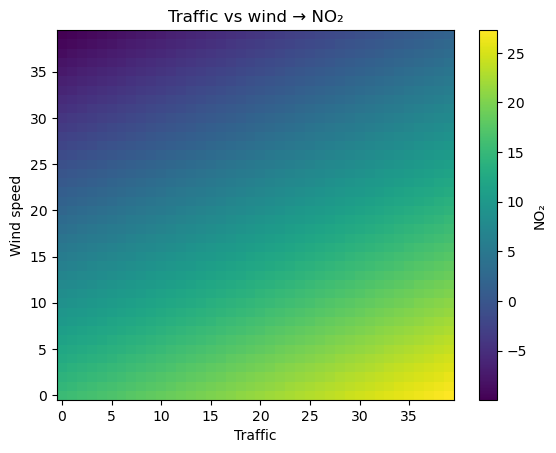

In [45]:
## Two-at-a-time sensitivity (heat map)

traffic_range = np.linspace(df["value"].min(), df["value"].max(), 40)
wind_range = np.linspace(df["wind_speed"].min(), df["wind_speed"].max(), 40)

Z = np.zeros((len(wind_range), len(traffic_range)))

base = df[weather_cols].median()

for i, w in enumerate(wind_range):
    for j, t in enumerate(traffic_range):
        x = base.copy()
        x["wind_speed"] = w
        x["value"] = t
        Z[i, j] = no2_model.predict(pd.DataFrame([x]))[0]

plt.imshow(Z, origin="lower", aspect="auto")
plt.colorbar(label="NO₂")
plt.xlabel("Traffic")
plt.ylabel("Wind speed")
plt.title("Traffic vs wind → NO₂")
plt.show()


## 3.  Modeling uncertainty and sampling

In [46]:
## Define variables again
weather_cols = [
    "temperature", "precipitation", "snow_depth",
    "wind_speed", "humidity", "pressure", "cloud_cover"
]

time_cols = ["hour", "dayofweek", "month"]

traffic_col = "value"

In [47]:
from scipy.stats import norm, triang
import numpy as np
import pandas as pd

N = 5000

# Traffic-triangular
v_min = df["value"].quantile(0.05)
v_mode = df["value"].median()
v_max = df["value"].quantile(0.95)
c = (v_mode - v_min) / (v_max - v_min)

traffic_tri = triang.rvs(c, loc=v_min, scale=v_max-v_min, size=N)

# Weather - normal
weather_norm = {}
for col in weather_cols:
    weather_norm[col] = np.random.normal(
        df[col].mean(),
        df[col].std(),
        N
    )
# Cloud cover - uniform
cloud_uni = np.random.uniform(
    df["cloud_cover"].min(),
    df["cloud_cover"].max(),
    N
)

# Empirical (precip + time)
precip_emp = np.random.choice(df["precipitation"], N)
hour_emp = np.random.choice(df["hour"], N)
day_emp = np.random.choice(df["dayofweek"], N)
month_emp = np.random.choice(df["month"], N)

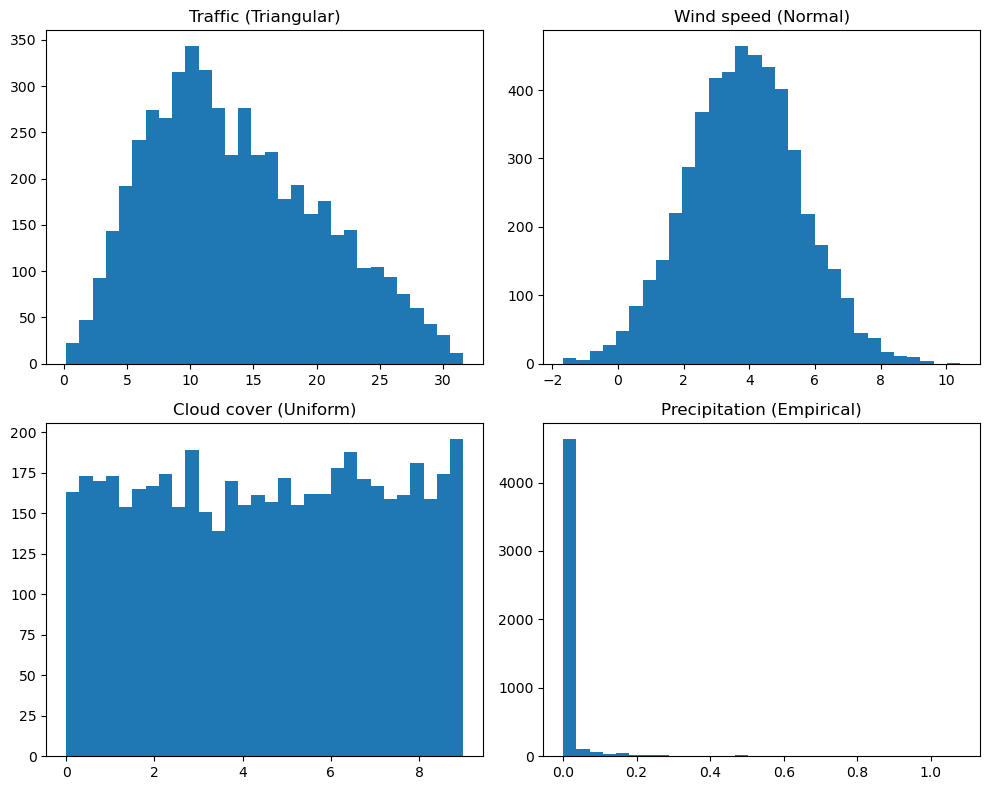

In [52]:
# histogram
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

axes[0, 0].hist(traffic_tri, bins=30)
axes[0, 0].set_title("Traffic (Triangular)")

axes[0, 1].hist(weather_norm["wind_speed"], bins=30)
axes[0, 1].set_title("Wind speed (Normal)")

axes[1, 0].hist(cloud_uni, bins=30)
axes[1, 0].set_title("Cloud cover (Uniform)")

axes[1, 1].hist(precip_emp, bins=30)
axes[1, 1].set_title("Precipitation (Empirical)")

plt.tight_layout()
plt.show()

In [53]:
# distribution table
dist_table = pd.DataFrame({
    "Variable": ["traffic", "wind_speed", "cloud_cover", "precipitation"],
    "Distribution": ["Triangular", "Normal", "Uniform", "Empirical"],
    "Parameters": [
        "5–50–95 percentiles",
        "mean & std from data",
        "min–max from data",
        "resampled observations"
    ]
})

dist_table

,Variable,Distribution,Parameters
0,traffic,Triangular,5–50–95 percentiles
1,wind_speed,Normal,mean & std from data
2,cloud_cover,Uniform,min–max from data
3,precipitation,Empirical,resampled observations


In [68]:
## sampling

N = 5000

v_min = df["value"].min()
v_max = df["value"].max()

w_min = df["wind_speed"].min()
w_max = df["wind_speed"].max()

print("Traffic range:", v_min, "to", v_max)
print("Wind range:", w_min, "to", w_max)


# Simple random sampling (uniform box)

traffic_rand = np.random.uniform(v_min, v_max, N)
wind_rand    = np.random.uniform(w_min, w_max, N)


# Latin Hypercube sampling (same box)

sampler = qmc.LatinHypercube(d=2, seed=42)
lhs = sampler.random(N)  # shape (N,2)

lhs_scaled = qmc.scale(lhs, l_bounds=[v_min, w_min], u_bounds=[v_max, w_max])
traffic_lhs = lhs_scaled[:, 0]
wind_lhs    = lhs_scaled[:, 1]


# Quasi-Monte Carlo (Sobol) sampling (same box)

sob = qmc.Sobol(d=2, scramble=True, seed=42)
qmc_s = sob.random(N)  # shape (N,2)

qmc_scaled = qmc.scale(qmc_s, l_bounds=[v_min, w_min], u_bounds=[v_max, w_max])
traffic_qmc = qmc_scaled[:, 0]
wind_qmc    = qmc_scaled[:, 1]

Traffic range: 0 to 30236
Wind range: 0.2 to 14.6


C:\Users\diept\anaconda3\Lib\site-packages\scipy\stats\_qmc.py:993: UserWarning:

The balance properties of Sobol' points require n to be a power of 2.



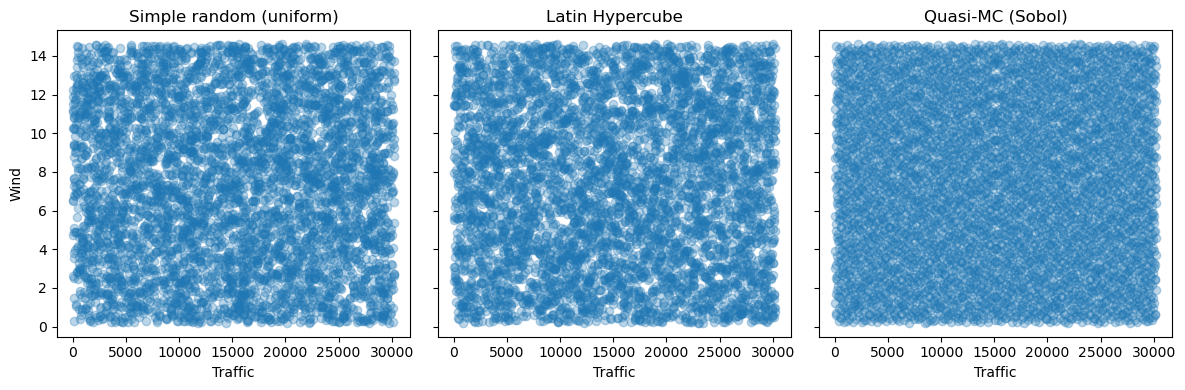

In [69]:
# Scatter plots
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)

axes[0].scatter(traffic_rand, wind_rand, alpha=0.3)
axes[0].set_title("Simple random (uniform)")
axes[0].set_xlabel("Traffic")
axes[0].set_ylabel("Wind")

axes[1].scatter(traffic_lhs, wind_lhs, alpha=0.3)
axes[1].set_title("Latin Hypercube")
axes[1].set_xlabel("Traffic")

axes[2].scatter(traffic_qmc, wind_qmc, alpha=0.3)
axes[2].set_title("Quasi-MC (Sobol)")
axes[2].set_xlabel("Traffic")

plt.tight_layout()
plt.show()

## 4. Global sensitivity analysis

In [70]:
from SALib.sample import sobol as sobol_sample
from SALib.analyze import sobol as sobol_analyze

from SALib.sample.morris import sample as morris_sample
from SALib.analyze.morris import analyze as morris_analyze

# define feature columns 
feature_cols = list(X_pollution.columns)

# Make sure all features are numeric
for c in feature_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# Fill missing with median
df[feature_cols] = df[feature_cols].fillna(df[feature_cols].median())

# Bounds = 5th–95th percentile
bounds = []
for c in feature_cols:
    lo = float(df[c].quantile(0.05))
    hi = float(df[c].quantile(0.95))
    if hi <= lo:
        hi = lo + 1e-6
    bounds.append([lo, hi])

problem = {"num_vars": len(feature_cols), "names": feature_cols, "bounds": bounds}

In [71]:
def predict_both(X_array):
    X = pd.DataFrame(X_array, columns=feature_cols)
    return no2_model.predict(X), bc_model.predict(X)


In [72]:
N = 600 

## Sobol
X_s = sobol_sample.sample(problem, N)
NO2_y, BC_y = predict_both(X_s)

Si_NO2 = sobol_analyze.analyze(problem, NO2_y, print_to_console=False)
Si_BC  = sobol_analyze.analyze(problem, BC_y,  print_to_console=False)

sobol_NO2 = pd.DataFrame({"Variable": feature_cols, "S1": Si_NO2["S1"], "ST": Si_NO2["ST"]}).sort_values("ST", ascending=False)
sobol_BC  = pd.DataFrame({"Variable": feature_cols, "S1": Si_BC["S1"],  "ST": Si_BC["ST"]}).sort_values("ST", ascending=False)

sobol_NO2, sobol_BC


C:\Users\diept\anaconda3\Lib\site-packages\scipy\stats\_qmc.py:993: UserWarning:

The balance properties of Sobol' points require n to be a power of 2.



(         Variable        S1            ST
 3      wind_speed  0.494518  4.929409e-01
 0     temperature  0.170673  1.579856e-01
 7            hour  0.129159  1.223442e-01
 2      snow_depth  0.082087  8.233585e-02
 8       dayofweek  0.063927  6.435460e-02
 4        humidity  0.040090  4.219007e-02
 6     cloud_cover  0.009242  1.161250e-02
 9           month  0.002042  1.840725e-03
 5        pressure  0.000620  3.719802e-04
 1   precipitation -0.000289  2.354830e-04
 10          value  0.000002  7.748736e-07,
          Variable        S1        ST
 2      snow_depth  0.443358  0.446867
 3      wind_speed  0.263351  0.259463
 4        humidity  0.097827  0.096910
 7            hour  0.086224  0.083744
 0     temperature  0.057976  0.052356
 5        pressure  0.017572  0.018466
 9           month  0.014200  0.013761
 8       dayofweek  0.010440  0.009858
 6     cloud_cover  0.000399  0.002086
 1   precipitation -0.000057  0.000009
 10          value -0.000003  0.000002)

In [73]:
## Morris
X_m = morris_sample(problem, N=20, num_levels=6, optimal_trajectories=10)
NO2_m, BC_m = predict_both(X_m)

m_NO2 = morris_analyze(problem, X_m, NO2_m, num_levels=6, print_to_console=False)
m_BC  = morris_analyze(problem, X_m, BC_m,  num_levels=6, print_to_console=False)

morris_NO2 = pd.DataFrame({"Variable": feature_cols, "mu_star": m_NO2["mu_star"], "sigma": m_NO2["sigma"]}).sort_values("mu_star", ascending=False)
morris_BC  = pd.DataFrame({"Variable": feature_cols, "mu_star": m_BC["mu_star"],  "sigma": m_BC["sigma"]}).sort_values("mu_star", ascending=False)

morris_NO2, morris_BC


(         Variable    mu_star         sigma
 3      wind_speed  10.036448  3.552714e-15
 0     temperature   5.758284  2.441369e-15
 7            hour   5.067677  2.134915e-15
 2      snow_depth   4.103055  1.256074e-15
 8       dayofweek   3.609270  2.631434e-15
 4        humidity   2.923096  2.477011e-15
 6     cloud_cover   1.534508  2.460368e-15
 9           month   0.609624  2.067454e-15
 5        pressure   0.272638  2.507783e-15
 1   precipitation   0.217979  2.729126e-15
 10          value   0.012562  2.184371e-15,
          Variable   mu_star         sigma
 2      snow_depth  0.311923  2.482534e-16
 3      wind_speed  0.237611  1.591750e-16
 4        humidity  0.144566  2.288783e-16
 7            hour  0.136817  1.575535e-16
 0     temperature  0.108172  2.311576e-16
 5        pressure  0.062684  1.210722e-16
 9           month  0.054393  2.102636e-16
 8       dayofweek  0.046097  2.713670e-16
 6     cloud_cover  0.021224  2.489770e-16
 1   precipitation  0.001417  2.285699e-1

In [74]:
sobol_NO2_clean = (
    sobol_NO2[["Variable", "S1", "ST"]]
    .round(3)
)

sobol_NO2_clean

,Variable,S1,ST
3,wind_speed,0.495,0.493
0,temperature,0.171,0.158
7,hour,0.129,0.122
2,snow_depth,0.082,0.082
8,dayofweek,0.064,0.064
4,humidity,0.040,0.042
6,cloud_cover,0.009,0.012
9,month,0.002,0.002
5,pressure,0.001,0.000
1,precipitation,-0.000,0.000


In [75]:
morris_NO2_clean = (
    morris_NO2[["Variable", "mu_star"]]
    .round(3)
)

morris_NO2_clean

,Variable,mu_star
3,wind_speed,10.036
0,temperature,5.758
7,hour,5.068
2,snow_depth,4.103
8,dayofweek,3.609
4,humidity,2.923
6,cloud_cover,1.535
9,month,0.610
5,pressure,0.273
1,precipitation,0.218


## 5. Visualize model behavior

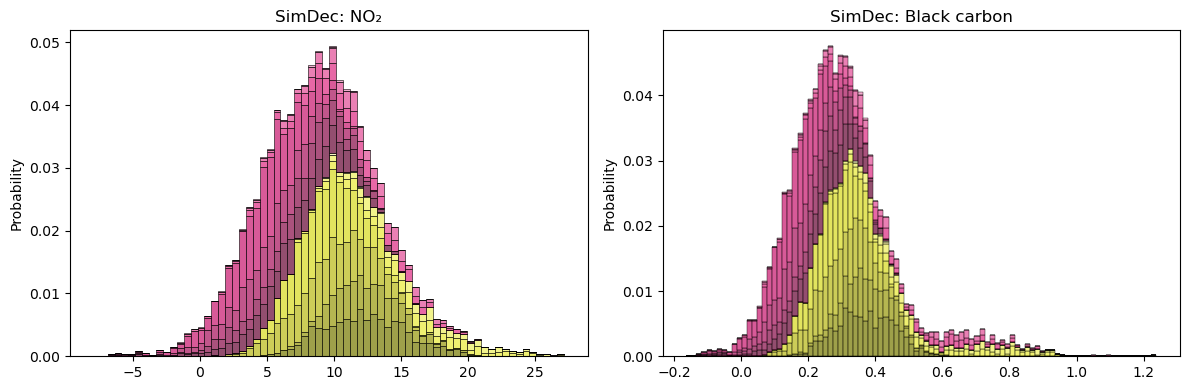

In [76]:
import matplotlib.pyplot as plt
import simdec
import pandas as pd
from IPython.display import display

# Predict outputs using fitted models
NO2_pred = no2_model.predict(df[feature_cols])
BC_pred  = bc_model.predict(df[feature_cols])

# Inputs used for states
X = pd.DataFrame({
    "traffic": df["value"],
    "wind_speed": df["wind_speed"],
    "snow_depth": df["snow_depth"],
    "temperature": df["temperature"]
})

# Build states using NO2
y_no2 = pd.Series(NO2_pred, name="NO2")
res = simdec.sensitivity_indices(inputs=X, output=y_no2)

dec_no2 = simdec.decomposition(
    inputs=X,
    output=y_no2,
    sensitivity_indices=getattr(res, "si", None)
)

# Use SAME state structure for BC
y_bc = pd.Series(BC_pred, name="BC")
dec_bc = simdec.decomposition(
    inputs=X,
    output=y_bc,
    sensitivity_indices=getattr(res, "si", None)
)

palette = simdec.palette(dec_no2.states)

#One figure with two panels
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

_ = simdec.visualization(bins=dec_no2.bins, palette=palette, ax=axes[0])
axes[0].set_title("SimDec: NO₂")

_ = simdec.visualization(bins=dec_bc.bins, palette=palette, ax=axes[1])
axes[1].set_title("SimDec: Black carbon")

plt.tight_layout()
plt.show()

#One shared legend table
legend_df, styler = simdec.tableau(
    var_names=dec_no2.var_names,
    statistic=dec_no2.statistic,
    states=dec_no2.states,
    bins=dec_no2.bins,
    palette=palette,
)
display(styler)

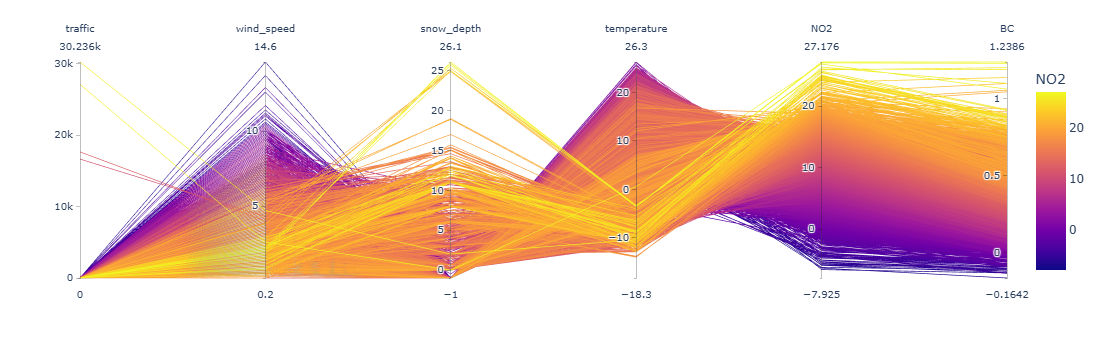

In [65]:
import plotly.express as px
import pandas as pd

# Predict outputs using existing models
NO2_pred = no2_model.predict(df[feature_cols])
BC_pred  = bc_model.predict(df[feature_cols])

# Build dataframe for visualization
df_pc = pd.DataFrame({
    "traffic": df["value"],
    "wind_speed": df["wind_speed"],
    "snow_depth": df["snow_depth"],
    "temperature": df["temperature"],
    "NO2": NO2_pred,
    "BC": BC_pred
})

# Parallel coordinates plot
fig = px.parallel_coordinates(
    df_pc,
    dimensions=["traffic", "wind_speed", "snow_depth", "temperature", "NO2", "BC"],
    color="NO2",
)

fig.show()